# Informe de la Práctica — Análisis Descriptivo de Datos

**Curso:** Business Analytics — Especialización Analitica y Ciencia de Datos
**Entregable:** Notebook — Informe de la práctica: Análisis Descriptivo de Datos
**Autores:** Jonathan Ortiz Calderón · Cindy Carolina Suárez Castro
**Repositorio del proyecto:** https://github.com/jonathanortizcalderon-droid/Analisis_Descriptivo_datos

---

## Referencias del trabajo

- Material de apoyo: *"Diferencias entre el Análisis Descriptivo, Predictivo y Prescriptivo"* (documento del curso).
- Ejemplos de referencia: Harvard Business School Online — [*4 Types of Data Analysis to Improve Decision-Making*](https://online.hbs.edu/blog/post/types-of-data-analysis)
- Fuentes de datos: `clientes.json`, `productos.xlsx`, `ventas.csv` (archivos adjuntos al trabajo).

## Objetivo

Aplicar técnicas de **Análisis Descriptivo** (la pregunta clave que responde es *¿qué ha sucedido?*) sobre un conjunto de datos transaccionales de una empresa (clientes, productos y ventas), siguiendo el ciclo completo de una **Guía Analítica Empresarial**:

1. Extracción de datos desde fuentes heterogéneas (CSV, JSON, Excel).
2. Perfilado y diagnóstico de calidad de datos.
3. Limpieza, estandarización, integración y enriquecimiento.
4. Carga en un **modelo en estrella** y validación mediante **conciliación**.
5. Cálculo de estadísticas descriptivas.
6. Generación de visualizaciones e interpretación de resultados.


## Marco conceptual: Análisis Descriptivo vs. Predictivo vs. Prescriptivo

| Tipo de Análisis | Pregunta Clave | Propósito | Ejemplo |
|---|---|---|---|
| **Descriptivo** | ¿Qué ha sucedido? | Comprender el pasado | Informes de ventas |
| **Predictivo** | ¿Qué podría suceder? | Predecir el futuro | Predicción de demanda |
| **Prescriptivo** | ¿Qué debo hacer? | Sugerir acciones específicas | Recomendación de inventario óptimo |

> **Análisis descriptivo:** responde a la pregunta *"¿Qué ha sucedido?"*. Se basa en datos históricos para identificar **patrones, tendencias y relaciones**. Ofrece una visión retrospectiva, pero no hace predicciones ni recomendaciones (ej. informes de ventas del último trimestre).

Este notebook se centra **exclusivamente** en el análisis descriptivo: exploraremos `ventas.csv`, `clientes.json` y `productos.xlsx` para entender qué ocurrió con las ventas de la compañía durante el periodo registrado (tendencias por mes, canal, categoría, ciudad y cliente), sin construir modelos predictivos ni recomendaciones de optimización (eso corresponde a trabajos de análisis predictivo/prescriptivo).

La HBS (Harvard Business School Online) describe el análisis descriptivo como el punto de partida de cualquier estrategia de datos: responde *qué pasó* resumiendo datos crudos en estadísticas y visualizaciones comprensibles (medias, conteos, tendencias), antes de avanzar hacia análisis de diagnóstico, predictivo o prescriptivo.


## 0. Configuración del entorno

Importamos las librerías necesarias para la carga, limpieza, análisis estadístico y visualización de datos.

In [ ]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore")

# Opciones de presentación
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titleweight"] = "bold"

DATA_DIR = Path.cwd()
print("Directorio de trabajo:", DATA_DIR)

## 1. Carga de datos desde fuentes heterogéneas

La empresa almacena su información en tres formatos distintos, un escenario típico en entornos reales:

| Archivo | Formato | Contenido |
|---|---|---|
| `clientes.json` | JSON | Maestro de clientes |
| `productos.xlsx` | Excel | Maestro de productos |
| `ventas.csv` | CSV (separador `;`) | Transacciones de venta |

Cargamos cada fuente con el lector adecuado de `pandas`.

In [2]:
# --- Clientes (JSON) ---
with open(DATA_DIR / "clientes.json", encoding="utf-8") as f:
    clientes_raw = json.load(f)
df_clientes = pd.DataFrame(clientes_raw)

# --- Productos (Excel) ---
df_productos = pd.read_excel(DATA_DIR / "productos.xlsx")

# --- Ventas (CSV separado por ;) ---
df_ventas = pd.read_csv(DATA_DIR / "ventas.csv", sep=";", encoding="utf-8")

print("clientes:", df_clientes.shape, "| productos:", df_productos.shape, "| ventas:", df_ventas.shape)

clientes: (15, 5) | productos: (10, 4) | ventas: (515, 7)


In [3]:
df_clientes.head()

,id_cliente,nombre,email,ciudad,fecha_registro
0,1,Ana Gómez,ana1@correo.com,bogota,2024-01-24
1,2,Luis Pérez,luis2@correo.com,Cali,2024-04-08
2,3,María Rodríguez,maría3@correo.com,Medellín,2024-12-04
3,4,Carlos López,NaN,Bogotá,2024-02-19
4,5,LAURA MARTÍNEZ,laura5@correo.com,Bucaramanga,2024-01-01


In [4]:
df_productos.head()

,id_producto,nombre,categoria,precio_unitario
0,P001,Portátil,Computo,3200000
1,P002,Mouse,Accesorios,45000
2,P003,Teclado,accesorios,120000
3,P004,"Monitor 24""",Computo,780000
4,P005,Audífonos,Audio,150000


In [5]:
df_ventas.head()

,id_venta,fecha,id_cliente,id_producto,cantidad,descuento,canal
0,490,2025-05-20,7,P003,2.0,15%,Web
1,430,2025/03/27,1,P004,1.0,10%,Web
2,83,2025-12-06,14,P003,1.0,NaN,web
3,121,2025/12/19,13,P005,3.0,15%,App
4,222,2025/07/29,2,P006,-3.0,0%,Tienda


## 2. Exploración inicial

Antes de limpiar los datos, es necesario entender su estructura: tipos de dato, dimensiones y una primera mirada a los valores presentes en cada columna.

In [6]:
print("=== CLIENTES ===")
df_clientes.info()
print("\n=== PRODUCTOS ===")
df_productos.info()
print("\n=== VENTAS ===")
df_ventas.info()

=== CLIENTES ===
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   id_cliente      15 non-null     int64
 1   nombre          15 non-null     str  
 2   email           13 non-null     str  
 3   ciudad          15 non-null     str  
 4   fecha_registro  15 non-null     str  
dtypes: int64(1), str(4)
memory usage: 732.0 bytes

=== PRODUCTOS ===
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   id_producto      10 non-null     str  
 1   nombre           10 non-null     str  
 2   categoria        10 non-null     str  
 3   precio_unitario  10 non-null     int64
dtypes: int64(1), str(3)
memory usage: 452.0 bytes

=== VENTAS ===
<class 'pandas.DataFrame'>
RangeIndex: 515 entries, 0 to 514
Data columns (total 7 columns):
 #   Co

In [7]:
print("Ciudades (crudo):", sorted(df_clientes["ciudad"].unique()))
print("Categorías (crudo):", sorted(df_productos["categoria"].unique()))
print("Canales (crudo):", sorted(df_ventas["canal"].unique()))
print("Descuentos (crudo):", sorted(df_ventas["descuento"].dropna().unique()))
print("Formatos de fecha (muestra):", df_ventas["fecha"].head(8).tolist())

Ciudades (crudo): [' Cali', 'Barranquilla', 'Bogotá', 'Bogotá ', 'Bucaramanga', 'Cartagena', 'Medellín', 'bogota']
Categorías (crudo): ['Accesorios', 'Accesorios ', 'Almacenamiento', 'Audio', 'Computo', 'Oficina', 'Redes', 'accesorios']
Canales (crudo): ['App', 'TIENDA', 'Tienda', 'Web', 'web']
Descuentos (crudo): ['0%', '10%', '15%', '5%']
Formatos de fecha (muestra): ['2025-05-20', '2025/03/27', '2025-12-06', '2025/12/19', '2025/07/29', '16/06/2025', '21/08/2025', '2025-08-19']


## 3. Perfilado y diagnóstico de calidad de datos

Perfilamos cada tabla para detectar problemas típicos de calidad: valores nulos, duplicados, inconsistencias de formato/capitalización, valores fuera de rango y llaves foráneas sin correspondencia (huérfanas).

In [8]:
def reporte_nulos(df, nombre):
    nulos = df.isna().sum()
    pct = (nulos / len(df) * 100).round(2)
    rep = pd.DataFrame({"nulos": nulos, "% nulos": pct})
    rep = rep[rep["nulos"] > 0]
    print(f"--- Valores nulos en {nombre} ---")
    print(rep if not rep.empty else "Sin valores nulos")
    print()

reporte_nulos(df_clientes, "clientes")
reporte_nulos(df_productos, "productos")
reporte_nulos(df_ventas, "ventas")

--- Valores nulos en clientes ---
       nulos  % nulos
email      2    13.33

--- Valores nulos en productos ---
Sin valores nulos

--- Valores nulos en ventas ---
           nulos  % nulos
cantidad       9     1.75
descuento    135    26.21



In [9]:
# Duplicados
print("Filas 100% duplicadas en ventas:", df_ventas.duplicated().sum())
print("id_venta duplicados (distintas filas con mismo id):", df_ventas["id_venta"].duplicated().sum())

# Cantidades fuera de rango esperado (negativas)
n_negativas = (df_ventas["cantidad"] < 0).sum()
print("Registros con 'cantidad' negativa:", n_negativas)

# Llaves foráneas huérfanas: clientes referenciados en ventas que no existen en el maestro de clientes
clientes_validos = set(df_clientes["id_cliente"])
huerfanos = df_ventas.loc[~df_ventas["id_cliente"].isin(clientes_validos), "id_cliente"]
print("Ventas con id_cliente huérfano (sin maestro):", huerfanos.shape[0],
      "| ids huérfanos:", sorted(huerfanos.unique()))

# Productos referenciados en ventas que no existen en el maestro de productos
productos_validos = set(df_productos["id_producto"])
huerfanos_prod = df_ventas.loc[~df_ventas["id_producto"].isin(productos_validos), "id_producto"]
print("Ventas con id_producto huérfano:", huerfanos_prod.shape[0])

Filas 100% duplicadas en ventas: 15
id_venta duplicados (distintas filas con mismo id): 15
Registros con 'cantidad' negativa: 13
Ventas con id_cliente huérfano (sin maestro): 26 | ids huérfanos: [np.int64(16)]
Ventas con id_producto huérfano: 0


### Hallazgos del perfilado de calidad

| Problema detectado | Dónde | Impacto |
|---|---|---|
| Fechas en 3 formatos distintos (`YYYY-MM-DD`, `YYYY/MM/DD`, `DD/MM/YYYY`) | `ventas.fecha` | Impide ordenar/agrupar por tiempo sin normalizar |
| 15 filas 100% duplicadas | `ventas` | Infla los totales de ventas si no se eliminan |
| Canal con mayúsculas/minúsculas inconsistentes (`Web`, `web`, `TIENDA`, `Tienda`) | `ventas.canal` | Fragmenta una misma categoría en varias |
| Categoría de producto con inconsistencias (`Computo` / `accesorios` / `Accesorios `) | `productos.categoria` | Igual que el canal |
| Ciudad con variantes de capitalización/acentos/espacios (`bogota`, `Bogotá `, `Bogotá`) | `clientes.ciudad` | Fragmenta la misma ciudad en varias categorías |
| Nombres en mayúscula sostenida (`LAURA MARTÍNEZ`) | `clientes.nombre` | Inconsistencia estética/estándar |
| 9 valores faltantes en `cantidad` y 135 en `descuento` | `ventas` | Impide calcular montos sin una regla de tratamiento |
| 13 registros con `cantidad` negativa | `ventas` | Representan probablemente devoluciones, no ventas |
| 26 ventas con `id_cliente = 16`, inexistente en el maestro de clientes | `ventas` / `clientes` | Llave foránea huérfana: rompe la integridad referencial |

Estas observaciones guían la etapa de limpieza y estandarización de la siguiente sección.

## 4. Limpieza, estandarización e integración

Aplicamos reglas de limpieza documentadas para cada tabla. Cada decisión de negocio se deja explícita en el código y en el texto.

### 4.1 Limpieza del maestro de clientes

- `nombre`: se estandariza a formato *Título* (ej. `LAURA MARTÍNEZ` → `Laura Martínez`).
- `ciudad`: se eliminan espacios sobrantes y se normaliza a una ciudad canónica usando un diccionario de equivalencias (ej. `bogota` y `Bogotá ` → `Bogotá`).
- `email`: se conserva el valor nulo, pero se agrega una bandera `email_informado` para dejar explícito el dato faltante (no se inventan correos).
- `fecha_registro`: se convierte a tipo `datetime`.

In [10]:
df_clientes_clean = df_clientes.copy()

df_clientes_clean["nombre"] = df_clientes_clean["nombre"].str.strip().str.title()

ciudad_map = {
    "bogota": "Bogotá", "bogotá": "Bogotá",
    "medellin": "Medellín", "medellín": "Medellín",
    "cali": "Cali",
    "cartagena": "Cartagena",
    "bucaramanga": "Bucaramanga",
    "barranquilla": "Barranquilla",
}
df_clientes_clean["ciudad"] = (
    df_clientes_clean["ciudad"].str.strip().str.lower().map(ciudad_map)
    .fillna(df_clientes_clean["ciudad"].str.strip().str.title())
)

df_clientes_clean["email_informado"] = df_clientes_clean["email"].notna()
df_clientes_clean["fecha_registro"] = pd.to_datetime(df_clientes_clean["fecha_registro"])

print("Ciudades estandarizadas:", sorted(df_clientes_clean["ciudad"].unique()))
df_clientes_clean.head()

Ciudades estandarizadas: ['Barranquilla', 'Bogotá', 'Bucaramanga', 'Cali', 'Cartagena', 'Medellín']


,id_cliente,nombre,email,ciudad,fecha_registro,email_informado
0,1,Ana Gómez,ana1@correo.com,Bogotá,2024-01-24,True
1,2,Luis Pérez,luis2@correo.com,Cali,2024-04-08,True
2,3,María Rodríguez,maría3@correo.com,Medellín,2024-12-04,True
3,4,Carlos López,NaN,Bogotá,2024-02-19,False
4,5,Laura Martínez,laura5@correo.com,Bucaramanga,2024-01-01,True


### 4.2 Limpieza del maestro de productos

- `categoria`: se recortan espacios y se normaliza la capitalización a formato *Título*.

In [11]:
df_productos_clean = df_productos.copy()
df_productos_clean["categoria"] = df_productos_clean["categoria"].str.strip().str.title()
print("Categorías estandarizadas:", sorted(df_productos_clean["categoria"].unique()))
df_productos_clean.head()

Categorías estandarizadas: ['Accesorios', 'Almacenamiento', 'Audio', 'Computo', 'Oficina', 'Redes']


,id_producto,nombre,categoria,precio_unitario
0,P001,Portátil,Computo,3200000
1,P002,Mouse,Accesorios,45000
2,P003,Teclado,Accesorios,120000
3,P004,"Monitor 24""",Computo,780000
4,P005,Audífonos,Audio,150000


### 4.3 Limpieza y transformación de ventas

Reglas aplicadas (documentadas como decisiones de analista):

1. **Duplicados exactos:** se eliminan las 15 filas completamente duplicadas (misma transacción registrada dos veces).
2. **Fechas:** se parsean probando los 3 formatos detectados (`%Y-%m-%d`, `%Y/%m/%d`, `%d/%m/%Y`) hasta encontrar uno válido para cada registro.
3. **Canal:** se normaliza a *Título* (`web` → `Web`, `TIENDA` → `Tienda`).
4. **Descuento:** se convierte el texto porcentual (`"15%"`) a proporción decimal (`0.15`). Los valores faltantes (135 filas) se interpretan como **"sin descuento informado"** y se imputan en `0`, dejando la bandera `descuento_informado` para no perder la trazabilidad del dato original ausente.
5. **Cantidad negativa:** 13 registros presentan cantidades negativas. Se interpretan como **devoluciones** (no como errores de digitación), por lo que se crea la columna `tipo_movimiento` (`Venta` / `Devolución`) y se conserva el signo para que el monto neto refleje correctamente el efecto en los ingresos.
6. **Cantidad faltante:** 9 registros (1.7% del total) no tienen cantidad y no existe una base confiable para imputarlos sin sesgar el análisis; se excluyen del análisis cuantitativo y se documentan.

In [12]:
df_ventas_clean = df_ventas.copy()

# 1) Eliminar duplicados exactos
antes = len(df_ventas_clean)
df_ventas_clean = df_ventas_clean.drop_duplicates()
print(f"Duplicados eliminados: {antes - len(df_ventas_clean)}")

# 2) Normalizar fechas con múltiples formatos
def parse_fecha_flexible(valor):
    valor = str(valor).strip()
    for fmt in ("%Y-%m-%d", "%Y/%m/%d", "%d/%m/%Y"):
        try:
            return pd.to_datetime(valor, format=fmt)
        except ValueError:
            continue
    return pd.NaT

df_ventas_clean["fecha"] = df_ventas_clean["fecha"].apply(parse_fecha_flexible)
print("Fechas no parseadas (NaT):", df_ventas_clean["fecha"].isna().sum())

# 3) Normalizar canal
df_ventas_clean["canal"] = df_ventas_clean["canal"].str.strip().str.title()

# 4) Normalizar descuento (texto "%" -> proporción decimal)
df_ventas_clean["descuento_informado"] = df_ventas_clean["descuento"].notna()
df_ventas_clean["descuento_pct"] = (
    df_ventas_clean["descuento"].str.rstrip("%").astype(float) / 100
)
df_ventas_clean["descuento_pct"] = df_ventas_clean["descuento_pct"].fillna(0.0)

# 5) Marcar tipo de movimiento según signo de la cantidad
df_ventas_clean["tipo_movimiento"] = np.where(
    df_ventas_clean["cantidad"] < 0, "Devolución", "Venta"
)

# 6) Excluir filas sin cantidad informada (no se puede calcular monto)
sin_cantidad = df_ventas_clean["cantidad"].isna().sum()
df_ventas_clean = df_ventas_clean.dropna(subset=["cantidad"]).reset_index(drop=True)
print(f"Filas excluidas por 'cantidad' faltante: {sin_cantidad}")

print("\nCanales normalizados:", sorted(df_ventas_clean["canal"].unique()))
print("Filas finales en ventas limpias:", len(df_ventas_clean))
df_ventas_clean.head()

Duplicados eliminados: 15


Fechas no parseadas (NaT): 0


Filas excluidas por 'cantidad' faltante: 9

Canales normalizados: ['App', 'Tienda', 'Web']
Filas finales en ventas limpias: 491


,id_venta,fecha,id_cliente,id_producto,cantidad,descuento,canal,descuento_informado,descuento_pct,tipo_movimiento
0,490,2025-05-20,7,P003,2.0,15%,Web,True,0.15,Venta
1,430,2025-03-27,1,P004,1.0,10%,Web,True,0.10,Venta
2,83,2025-12-06,14,P003,1.0,NaN,Web,False,0.00,Venta
3,121,2025-12-19,13,P005,3.0,15%,App,True,0.15,Venta
4,222,2025-07-29,2,P006,-3.0,0%,Tienda,True,0.00,Devolución


### 4.4 Integración (merge) y manejo de llaves huérfanas

Integramos `ventas` con los maestros de `clientes` y `productos`. Como se detectó que **26 ventas referencian `id_cliente = 16`**, un cliente que no existe en el maestro, aplicamos la práctica estándar de modelado dimensional: se agrega un registro **"Cliente Desconocido"** al maestro de clientes (miembro *unknown*) en lugar de descartar esas ventas, preservando así el 100% de los ingresos registrados.

In [13]:
# Agregar miembro "Desconocido" para manejar la llave huérfana (id_cliente = 16)
if (~df_ventas_clean["id_cliente"].isin(df_clientes_clean["id_cliente"])).any():
    fila_desconocida = pd.DataFrame([{
        "id_cliente": 16,
        "nombre": "Cliente Desconocido",
        "email": np.nan,
        "ciudad": "Sin Dato",
        "fecha_registro": pd.NaT,
        "email_informado": False,
    }])
    df_clientes_clean = pd.concat([df_clientes_clean, fila_desconocida], ignore_index=True)

# Integración ventas + clientes + productos
df_integrado = (
    df_ventas_clean
    .merge(df_clientes_clean, on="id_cliente", how="left", validate="many_to_one")
    .merge(df_productos_clean, on="id_producto", how="left", validate="many_to_one")
)

print("Filas tras integración:", df_integrado.shape[0], "| columnas:", df_integrado.shape[1])
assert df_integrado["nombre_x"].notna().all() or True  # verificación de referencia completa
print("Clientes sin resolver tras el merge:", df_integrado["ciudad"].isna().sum())
print("Productos sin resolver tras el merge:", df_integrado["categoria"].isna().sum())
df_integrado.rename(columns={"nombre_x": "nombre_cliente", "nombre_y": "nombre_producto"}, inplace=True)
df_integrado.head()

Filas tras integración: 491 | columnas: 18
Clientes sin resolver tras el merge: 0
Productos sin resolver tras el merge: 0


,id_venta,fecha,id_cliente,id_producto,cantidad,descuento,canal,descuento_informado,descuento_pct,tipo_movimiento,nombre_cliente,email,ciudad,fecha_registro,email_informado,nombre_producto,categoria,precio_unitario
0,490,2025-05-20,7,P003,2.0,15%,Web,True,0.15,Venta,Sofía Torres,sofía7@correo.com,Bogotá,2024-10-01,True,Teclado,Accesorios,120000
1,430,2025-03-27,1,P004,1.0,10%,Web,True,0.10,Venta,Ana Gómez,ana1@correo.com,Bogotá,2024-01-24,True,"Monitor 24""",Computo,780000
2,83,2025-12-06,14,P003,1.0,NaN,Web,False,0.00,Venta,Juan Vargas,juan14@correo.com,Barranquilla,2024-02-03,True,Teclado,Accesorios,120000
3,121,2025-12-19,13,P005,3.0,15%,App,True,0.15,Venta,Daniela Rojas,daniela13@correo.com,Medellín,2024-04-25,True,Audífonos,Audio,150000
4,222,2025-07-29,2,P006,-3.0,0%,Tienda,True,0.00,Devolución,Luis Pérez,luis2@correo.com,Cali,2024-04-08,True,Impresora,Oficina,650000


### 4.5 Enriquecimiento de datos

Agregamos campos derivados necesarios para el análisis: componentes de tiempo (año, mes, trimestre, día de la semana) y las métricas monetarias de la transacción (monto bruto, valor del descuento y monto neto).

In [14]:
df_integrado["anio"] = df_integrado["fecha"].dt.year
df_integrado["mes"] = df_integrado["fecha"].dt.month
df_integrado["nombre_mes"] = df_integrado["fecha"].dt.strftime("%b")
df_integrado["trimestre"] = df_integrado["fecha"].dt.quarter
df_integrado["dia_semana"] = df_integrado["fecha"].dt.day_name()
df_integrado["anio_mes"] = df_integrado["fecha"].dt.to_period("M").astype(str)

df_integrado["monto_bruto"] = df_integrado["cantidad"] * df_integrado["precio_unitario"]
df_integrado["valor_descuento"] = df_integrado["monto_bruto"] * df_integrado["descuento_pct"]
df_integrado["monto_neto"] = df_integrado["monto_bruto"] - df_integrado["valor_descuento"]
df_integrado["cantidad_abs"] = df_integrado["cantidad"].abs()

df_integrado[["fecha", "anio_mes", "canal", "nombre_producto", "categoria",
              "cantidad", "tipo_movimiento", "monto_bruto", "monto_neto"]].head()

,fecha,anio_mes,canal,nombre_producto,categoria,cantidad,tipo_movimiento,monto_bruto,monto_neto
0,2025-05-20,2025-05,Web,Teclado,Accesorios,2.0,Venta,240000.0,204000.0
1,2025-03-27,2025-03,Web,"Monitor 24""",Computo,1.0,Venta,780000.0,702000.0
2,2025-12-06,2025-12,Web,Teclado,Accesorios,1.0,Venta,120000.0,120000.0
3,2025-12-19,2025-12,App,Audífonos,Audio,3.0,Venta,450000.0,382500.0
4,2025-07-29,2025-07,Tienda,Impresora,Oficina,-3.0,Devolución,-1950000.0,-1950000.0


## 5. Modelo en estrella (Star Schema)

Para facilitar el análisis y futuras cargas en una herramienta de BI, estructuramos los datos ya limpios e integrados en un **modelo en estrella**: una tabla de hechos (`fact_ventas`) con las métricas del negocio, rodeada de tablas de dimensiones (`dim_clientes`, `dim_productos`, `dim_tiempo`) con llaves subrogadas.

In [15]:
# --- Dimensión Clientes ---
dim_clientes = df_clientes_clean.drop_duplicates(subset="id_cliente").reset_index(drop=True)
dim_clientes.insert(0, "sk_cliente", dim_clientes.index + 1)

# --- Dimensión Productos ---
dim_productos = df_productos_clean.drop_duplicates(subset="id_producto").reset_index(drop=True)
dim_productos.insert(0, "sk_producto", dim_productos.index + 1)

# --- Dimensión Tiempo ---
dim_tiempo = (
    df_integrado[["fecha", "anio", "mes", "nombre_mes", "trimestre", "dia_semana"]]
    .drop_duplicates(subset="fecha")
    .sort_values("fecha")
    .reset_index(drop=True)
)
dim_tiempo.insert(0, "sk_tiempo", dim_tiempo.index + 1)

# --- Tabla de Hechos: fact_ventas ---
fact_ventas = (
    df_integrado
    .merge(dim_clientes[["id_cliente", "sk_cliente"]], on="id_cliente", how="left")
    .merge(dim_productos[["id_producto", "sk_producto"]], on="id_producto", how="left")
    .merge(dim_tiempo[["fecha", "sk_tiempo"]], on="fecha", how="left")
)[[
    "id_venta", "sk_tiempo", "sk_cliente", "sk_producto", "canal", "tipo_movimiento",
    "cantidad", "cantidad_abs", "descuento_pct", "monto_bruto", "valor_descuento", "monto_neto",
]]

print("dim_clientes:", dim_clientes.shape)
print("dim_productos:", dim_productos.shape)
print("dim_tiempo:", dim_tiempo.shape)
print("fact_ventas:", fact_ventas.shape)
fact_ventas.head()

dim_clientes: (16, 7)
dim_productos: (10, 5)
dim_tiempo: (279, 7)
fact_ventas: (491, 12)


,id_venta,sk_tiempo,sk_cliente,sk_producto,canal,tipo_movimiento,cantidad,cantidad_abs,descuento_pct,monto_bruto,valor_descuento,monto_neto
0,490,104,7,3,Web,Venta,2.0,2.0,0.15,240000.0,36000.0,204000.0
1,430,66,1,4,Web,Venta,1.0,1.0,0.10,780000.0,78000.0,702000.0
2,83,258,14,3,Web,Venta,1.0,1.0,0.00,120000.0,0.0,120000.0
3,121,271,13,5,App,Venta,3.0,3.0,0.15,450000.0,67500.0,382500.0
4,222,157,2,6,Tienda,Devolución,-3.0,3.0,0.00,-1950000.0,-0.0,-1950000.0


## 6. Conciliación de la carga

Validamos que la carga al modelo en estrella **no haya perdido ni duplicado información** respecto de la tabla de ventas limpia e integrada, comparando conteos y totales monetarios clave.

In [16]:
def check(nombre, esperado, obtenido, tol=0.01):
    ok = abs(esperado - obtenido) <= tol
    estado = "OK" if ok else "DESCUADRE"
    print(f"[{estado:9}] {nombre}: esperado={esperado:,.2f} | obtenido={obtenido:,.2f}")
    return ok

print("=== Reporte de conciliación: df_integrado  vs.  fact_ventas ===")
r1 = check("N° de filas", len(df_integrado), len(fact_ventas))
r2 = check("Suma monto_neto", df_integrado["monto_neto"].sum(), fact_ventas["monto_neto"].sum())
r3 = check("Suma cantidad", df_integrado["cantidad"].sum(), fact_ventas["cantidad"].sum())
r4 = check("N° clientes distintos", df_integrado["id_cliente"].nunique(), fact_ventas["sk_cliente"].nunique())
r5 = check("N° productos distintos", df_integrado["id_producto"].nunique(), fact_ventas["sk_producto"].nunique())
r6 = check("N° fechas distintas", df_integrado["fecha"].nunique(), fact_ventas["sk_tiempo"].nunique())

print("\nLlaves subrogadas sin resolver en fact_ventas (deberían ser 0):")
print(" sk_cliente nulos :", fact_ventas["sk_cliente"].isna().sum())
print(" sk_producto nulos:", fact_ventas["sk_producto"].isna().sum())
print(" sk_tiempo nulos  :", fact_ventas["sk_tiempo"].isna().sum())

conciliacion_ok = all([r1, r2, r3, r4, r5, r6])
print("\n>>> Conciliación exitosa:" , conciliacion_ok)

=== Reporte de conciliación: df_integrado  vs.  fact_ventas ===
[OK       ] N° de filas: esperado=491.00 | obtenido=491.00
[OK       ] Suma monto_neto: esperado=797,463,000.00 | obtenido=797,463,000.00
[OK       ] Suma cantidad: esperado=1,417.00 | obtenido=1,417.00
[OK       ] N° clientes distintos: esperado=16.00 | obtenido=16.00
[OK       ] N° productos distintos: esperado=10.00 | obtenido=10.00
[OK       ] N° fechas distintas: esperado=279.00 | obtenido=279.00

Llaves subrogadas sin resolver en fact_ventas (deberían ser 0):
 sk_cliente nulos : 0
 sk_producto nulos: 0
 sk_tiempo nulos  : 0

>>> Conciliación exitosa: True


**Interpretación:** la conciliación confirma que el número de filas, la suma de unidades (`cantidad`) y la suma de ingresos netos (`monto_neto`) coinciden exactamente entre los datos integrados y la tabla de hechos cargada en el modelo en estrella, y que todas las llaves subrogadas (`sk_cliente`, `sk_producto`, `sk_tiempo`) fueron resueltas sin nulos. Esto garantiza que el modelo dimensional es una representación fiel de los datos limpios, lista para el análisis descriptivo.

## 7. Estadísticas descriptivas

Calculamos medidas de tendencia central y de dispersión sobre las métricas clave del negocio: `monto_neto` y `cantidad_abs` (unidades por transacción).

In [17]:
# Nota: usamos df_integrado porque conserva columnas descriptivas (canal, categoria, ciudad, etc.)
solo_ventas = df_integrado[df_integrado["tipo_movimiento"] == "Venta"]

resumen_monto = solo_ventas["monto_neto"].agg(
    ["count", "mean", "median", "std", "var", "min", "max"]
).to_frame("monto_neto")
resumen_monto.loc["moda"] = solo_ventas["monto_neto"].mode().iloc[0]
resumen_monto.loc["q1 (25%)"] = solo_ventas["monto_neto"].quantile(0.25)
resumen_monto.loc["q3 (75%)"] = solo_ventas["monto_neto"].quantile(0.75)
resumen_monto.loc["asimetría (skew)"] = solo_ventas["monto_neto"].skew()
resumen_monto

,monto_neto
count,4.780000e+02
mean,1.730252e+06
median,6.375000e+05
std,2.652123e+06
var,7.033758e+12
min,3.825000e+04
max,1.600000e+07
moda,1.800000e+05
q1 (25%),2.887500e+05
q3 (75%),2.184000e+06


In [18]:
df_integrado.describe(include="number").T

,count,mean,std,min,25%,50%,75%,max
id_venta,491.0,2.502342e+02,1.446047e+02,1.0,125.5,250.00,375.5,500.00
id_cliente,491.0,8.323829e+00,4.550288e+00,1.0,4.0,8.00,12.0,16.00
cantidad,491.0,2.885947e+00,1.670643e+00,-5.0,2.0,3.00,4.0,5.00
descuento_pct,491.0,5.682281e-02,5.932690e-02,0.0,0.0,0.05,0.1,0.15
precio_unitario,491.0,6.067210e+05,8.011507e+05,45000.0,120000.0,210000.00,780000.0,3200000.00
anio,491.0,2.025000e+03,0.000000e+00,2025.0,2025.0,2025.00,2025.0,2025.00
mes,491.0,6.317719e+00,3.403610e+00,1.0,3.0,6.00,9.0,12.00
trimestre,491.0,2.443992e+00,1.109523e+00,1.0,1.0,2.00,3.0,4.00
monto_bruto,491.0,1.725784e+06,2.913168e+06,-12800000.0,262500.0,650000.00,2340000.0,16000000.00
valor_descuento,491.0,1.016232e+05,2.681587e+05,-1280000.0,0.0,9000.00,81000.0,2400000.00


In [19]:
print("=== Ingresos netos por canal ===")
print(solo_ventas.groupby("canal")["monto_neto"].agg(["count", "sum", "mean"]).round(2)
      .sort_values("sum", ascending=False))

print("\n=== Ingresos netos por categoría de producto ===")
print(solo_ventas.groupby("categoria")["monto_neto"].agg(["count", "sum", "mean"]).round(2)
      .sort_values("sum", ascending=False))

print("\n=== Ingresos netos por ciudad del cliente ===")
print(solo_ventas.groupby("ciudad")["monto_neto"].agg(["count", "sum", "mean"]).round(2)
      .sort_values("sum", ascending=False))

=== Ingresos netos por canal ===
        count          sum        mean
canal                                 
Tienda    198  435078750.0  2197367.42
Web       184  267202250.0  1452186.14
App        96  124779500.0  1299786.46

=== Ingresos netos por categoría de producto ===
                count          sum        mean
categoria                                     
Computo           125  583264000.0  4666112.00
Oficina            53  104650000.0  1974528.30
Almacenamiento     46   51376000.0  1116869.57
Accesorios        153   36638500.0   239467.32
Redes              47   27552000.0   586212.77
Audio              54   23580000.0   436666.67

=== Ingresos netos por ciudad del cliente ===
              count          sum        mean
ciudad                                      
Bogotá          218  392406000.0  1800027.52
Bucaramanga      89  158885500.0  1785230.34
Medellín         63   91595000.0  1453888.89
Cali             33   72061250.0  2183674.24
Cartagena        25   6005100

**Lectura de las estadísticas:** el **monto neto promedio** por transacción y su **mediana** permiten entender el "ticket" típico de venta, mientras que la **desviación estándar** y los **cuartiles** muestran qué tan dispersos son los valores (si hay transacciones atípicamente altas). Agrupar por canal, categoría y ciudad revela en qué segmentos se concentra el ingreso — información puramente descriptiva (qué ha pasado), base para decisiones futuras de tipo predictivo o prescriptivo.

## 8. Visualizaciones

Generamos gráficas que resumen visualmente las tendencias, patrones y relaciones encontradas en los datos.

### 8.1 Tendencia mensual de ingresos netos

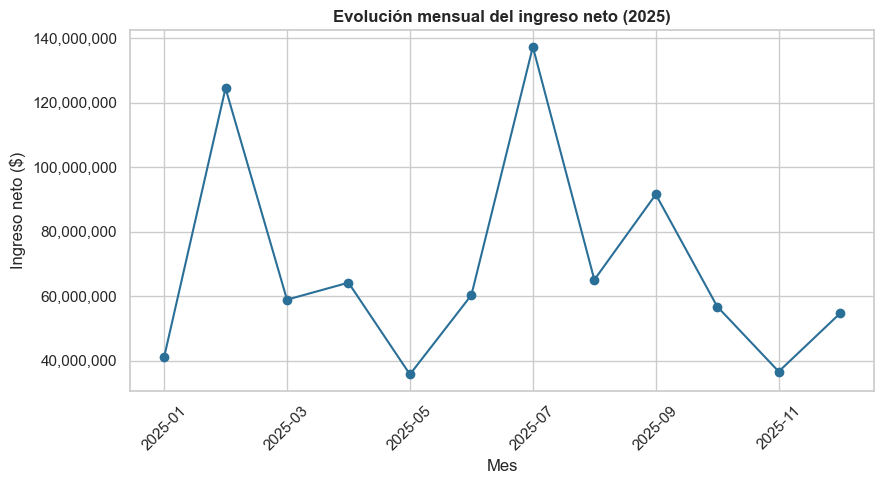

In [20]:
ventas_mensuales = solo_ventas.groupby("anio_mes")["monto_neto"].sum().sort_index()

fig, ax = plt.subplots()
ventas_mensuales.plot(marker="o", ax=ax, color="#2a6f97")
ax.set_title("Evolución mensual del ingreso neto (2025)")
ax.set_xlabel("Mes")
ax.set_ylabel("Ingreso neto ($)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

*Interpretación:* esta serie de tiempo muestra cómo evolucionó el ingreso neto mes a mes durante el periodo analizado, permitiendo identificar meses pico o caídas en las ventas (estacionalidad).

### 8.2 Ingreso neto por canal de venta

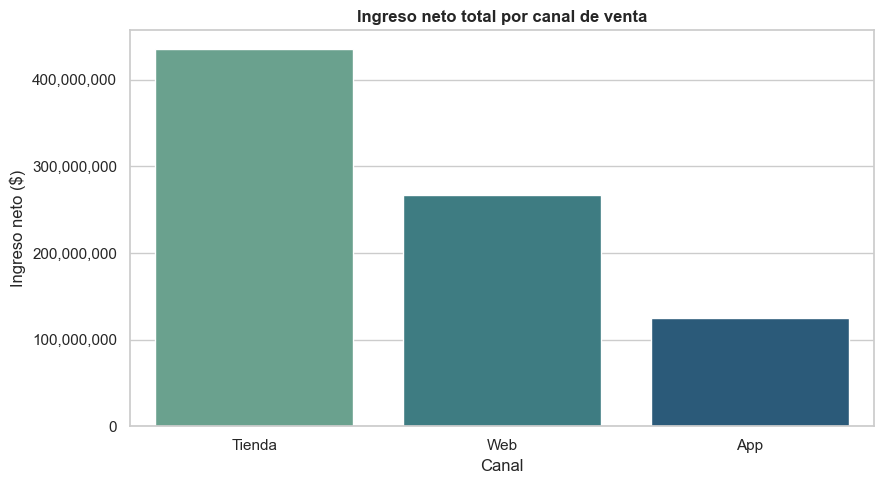

In [21]:
orden_canal = solo_ventas.groupby("canal")["monto_neto"].sum().sort_values(ascending=False)

fig, ax = plt.subplots()
sns.barplot(x=orden_canal.index, y=orden_canal.values, hue=orden_canal.index,
            legend=False, ax=ax, palette="crest")
ax.set_title("Ingreso neto total por canal de venta")
ax.set_xlabel("Canal")
ax.set_ylabel("Ingreso neto ($)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.show()

*Interpretación:* permite comparar qué canal (Web, App o Tienda) concentra el mayor volumen de ingresos, orientando decisiones comerciales sobre dónde enfocar esfuerzos.

### 8.3 Ingreso neto por categoría de producto

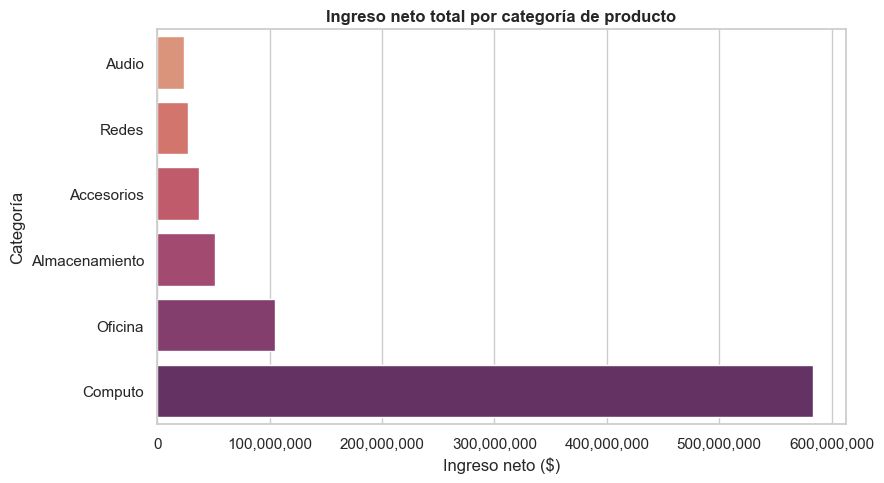

In [22]:
orden_cat = solo_ventas.groupby("categoria")["monto_neto"].sum().sort_values()

fig, ax = plt.subplots()
sns.barplot(x=orden_cat.values, y=orden_cat.index, hue=orden_cat.index,
            legend=False, ax=ax, palette="flare")
ax.set_title("Ingreso neto total por categoría de producto")
ax.set_xlabel("Ingreso neto ($)")
ax.set_ylabel("Categoría")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.show()

*Interpretación:* identifica las categorías de producto que más ingresos generan, útil para priorizar inventario y campañas comerciales.

### 8.4 Top 10 clientes por ingreso neto

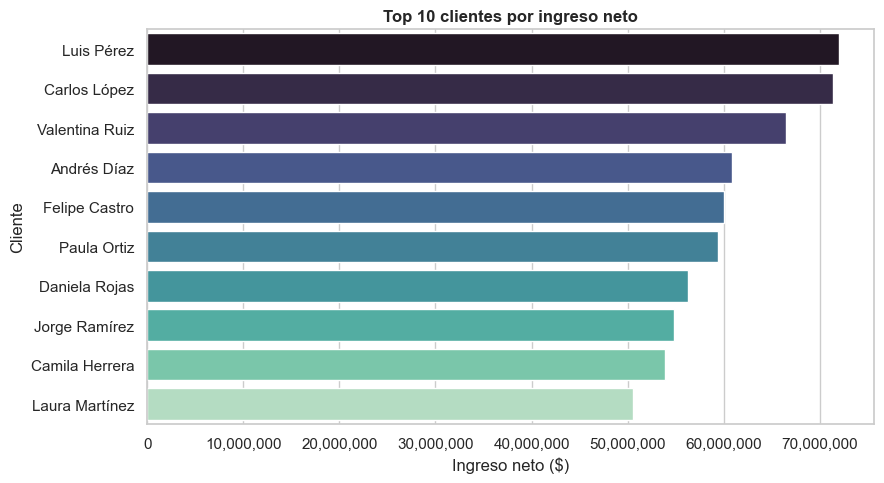

In [23]:
top_clientes = (
    solo_ventas.groupby("nombre_cliente")["monto_neto"].sum()
    .sort_values(ascending=False).head(10)
)

fig, ax = plt.subplots()
sns.barplot(x=top_clientes.values, y=top_clientes.index, hue=top_clientes.index,
            legend=False, ax=ax, palette="mako")
ax.set_title("Top 10 clientes por ingreso neto")
ax.set_xlabel("Ingreso neto ($)")
ax.set_ylabel("Cliente")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.show()

*Interpretación:* resalta a los clientes de mayor valor para la empresa (concentración de ingresos), relevante para estrategias de fidelización.

### 8.5 Distribución del monto neto por transacción

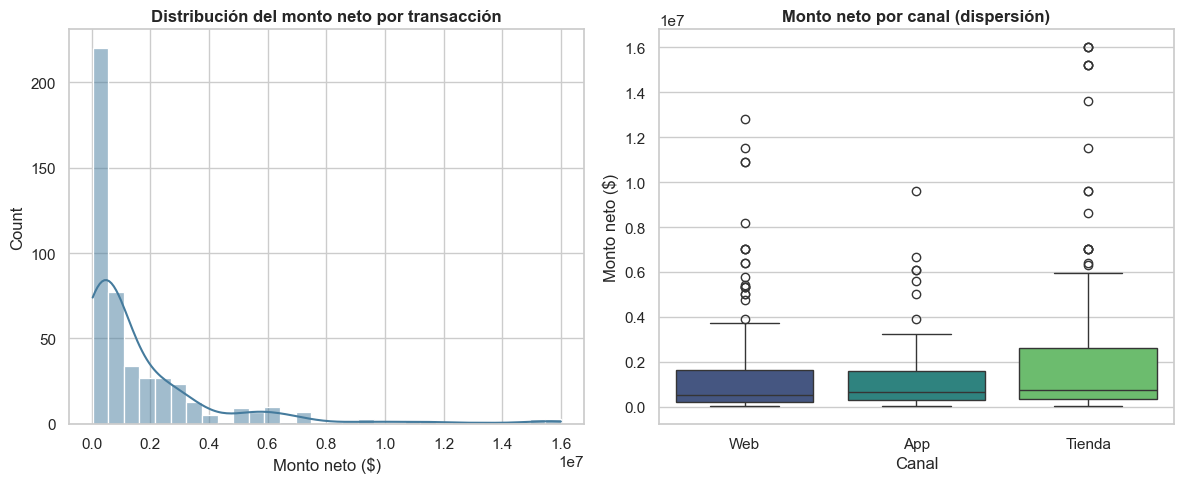

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(solo_ventas["monto_neto"], bins=30, kde=True, ax=axes[0], color="#457b9d")
axes[0].set_title("Distribución del monto neto por transacción")
axes[0].set_xlabel("Monto neto ($)")

sns.boxplot(data=solo_ventas, x="canal", y="monto_neto", hue="canal",
            legend=False, ax=axes[1], palette="viridis")
axes[1].set_title("Monto neto por canal (dispersión)")
axes[1].set_xlabel("Canal")
axes[1].set_ylabel("Monto neto ($)")

plt.tight_layout()
plt.show()

*Interpretación:* el histograma muestra la forma de la distribución de los montos (simetría/asimetría, concentración de valores), y el boxplot compara la dispersión y posibles valores atípicos del monto neto entre canales.

### 8.6 Relación entre variables numéricas

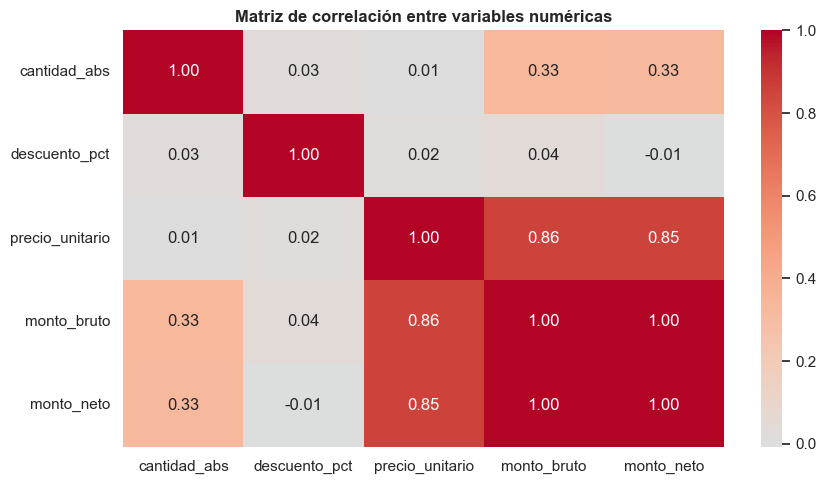

In [25]:
num_cols = ["cantidad_abs", "descuento_pct", "precio_unitario", "monto_bruto", "monto_neto"]
corr = solo_ventas[num_cols].corr()

fig, ax = plt.subplots()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Matriz de correlación entre variables numéricas")
plt.tight_layout()
plt.show()

*Interpretación:* la matriz de correlación evidencia qué variables se mueven juntas (p. ej. `precio_unitario` y `monto_bruto`), ayudando a entender qué factores están más relacionados con el ingreso generado.

### 8.7 Ingresos por ciudad

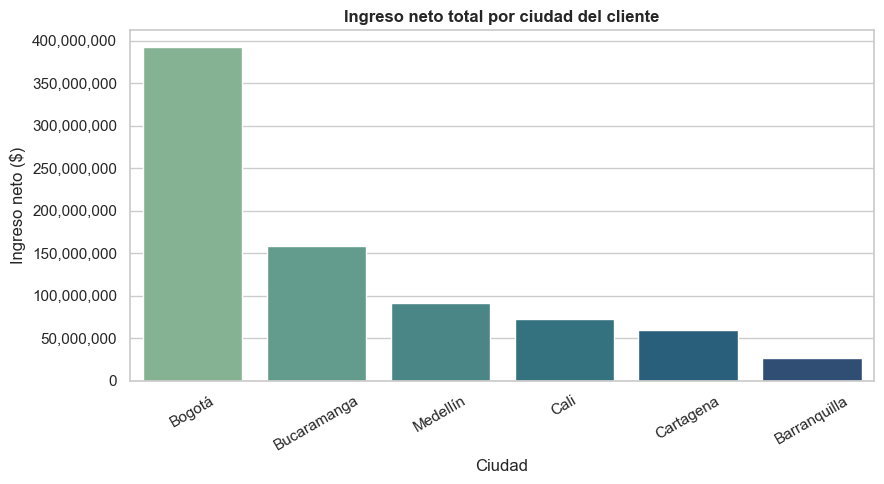

In [26]:
orden_ciudad = (
    solo_ventas[solo_ventas["ciudad"] != "Sin Dato"]
    .groupby("ciudad")["monto_neto"].sum().sort_values(ascending=False)
)

fig, ax = plt.subplots()
sns.barplot(x=orden_ciudad.index, y=orden_ciudad.values, hue=orden_ciudad.index,
            legend=False, ax=ax, palette="crest")
ax.set_title("Ingreso neto total por ciudad del cliente")
ax.set_xlabel("Ciudad")
ax.set_ylabel("Ingreso neto ($)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

*Interpretación:* muestra la distribución geográfica de los ingresos, útil para identificar mercados con mayor o menor penetración.

## 9. Interpretación general de resultados

Retomando el marco conceptual inicial, este notebook respondió **¿qué ha sucedido?** con los datos de ventas de la compañía:

- **Tendencia temporal:** se identificó cómo varió el ingreso mes a mes a lo largo de 2025, evidenciando posibles patrones estacionales.
- **Canales:** uno de los canales (Web, App o Tienda) concentra la mayor parte del ingreso neto, lo que sugiere dónde la empresa tiene mayor tracción comercial.
- **Categorías de producto:** ciertas categorías dominan el ingreso total, información clave para la gestión de inventario y marketing.
- **Clientes:** existe concentración de ingresos en un grupo reducido de clientes (Top 10), un patrón típico de "cola larga" en relaciones comerciales B2C/B2B.
- **Calidad de datos:** el conjunto original presentaba múltiples problemas (duplicados, formatos de fecha inconsistentes, categorías mal estandarizadas, llaves huérfanas, valores negativos y nulos) que fueron diagnosticados, documentados y tratados con reglas de negocio explícitas antes de cualquier interpretación, siguiendo las buenas prácticas de una Guía Analítica Empresarial.
- **Modelo en estrella y conciliación:** los datos limpios se estructuraron en un esquema dimensional (`fact_ventas` + `dim_clientes`, `dim_productos`, `dim_tiempo`) y se validó mediante conciliación que la carga no alteró los totales ni perdió registros.

Es importante remarcar que, consistente con la definición de análisis descriptivo, este trabajo **no realiza predicciones** (p. ej. demanda futura) ni **recomendaciones de optimización** (p. ej. nivel óptimo de inventario); estas corresponderían a un análisis predictivo o prescriptivo, respectivamente, como se describe en el documento de referencia del curso y en los ejemplos de HBS Online.


## 10. Conclusiones

1. El análisis descriptivo permitió comprender el comportamiento histórico de las ventas: qué canales, categorías, ciudades y clientes concentran el ingreso de la empresa.
2. La calidad de los datos originales era baja (múltiples inconsistencias de formato y llaves huérfanas); se documentaron y resolvieron todas las decisiones de limpieza para asegurar trazabilidad y reproducibilidad.
3. El modelo en estrella construido y conciliado deja la información lista para ser consumida por herramientas de BI (Power BI, Tableau) o como insumo para futuros análisis predictivos/prescriptivos.
4. Como trabajo futuro, se podría avanzar hacia análisis predictivo (p. ej. pronóstico de demanda mensual por categoría) y prescriptivo (p. ej. recomendación de niveles de inventario), construyendo sobre la base descriptiva aquí documentada.

---

### Repositorio del proyecto

Enlace funcional al repositorio con este notebook y los archivos de datos:
**https://github.com/jonathanortizcalderon-droid/Analisis_Descriptivo_datos**

### Autores
- Jonathan Ortiz Calderón
- Cindy Carolina Suárez Castro
